# Gráfico 4: top 15 mercados por revalorización real de la vivienda (tiene en cuenta la inflación)--> Incremento precio vivienda - inflación = revalorización real

Muestra los 15 países donde más ha crecido de media al año el precio de la vivienda descontada la inflación (real = precio - inflación), 2015-2024, con España al final con su puesto.

**Datos:** `merge_vivienda_inflacion.csv` (carpeta `data/Mergeados`; 57 países, 2015-2024).

## 1 Librerías y funciones propias (src/utils/archivos.py)

In [1]:
import sys
sys.path.append("..")
from utils.archivos import cargar_dataset, guardar_grafico

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 2 Cargo los datos

In [2]:
vivienda_real = cargar_dataset("merge_vivienda_inflacion.csv")
vivienda_real.head()

,pais,iso3,anio,crec._precio_(%),inflacion_(%),crec_real_(%)
0,Australia,AUS,2015,9.0,1.5,7.5
1,Australia,AUS,2016,5.5,1.3,4.2
2,Australia,AUS,2017,8.4,1.9,6.5
3,Australia,AUS,2018,-1.4,1.9,-3.3
4,Australia,AUS,2019,-4.0,1.6,-5.6


## 3 Calculo el ranking (con España al final)

In [3]:
ranking = vivienda_real.groupby("pais")["crec_real_(%)"].mean().round(1)
ranking = ranking.sort_values(ascending=False).reset_index()
ranking["puesto"] = ranking.index + 1
ranking["etiqueta"] = "#" + ranking["puesto"].astype(str) + " " + ranking["pais"] + " (" + ranking["crec_real_(%)"].astype(str) + " %)"
top15_real = pd.concat([ranking.head(15), ranking[ranking["pais"] == "Spain"]])
top15_real

,pais,crec_real_(%),puesto,etiqueta
0,Türkiye,13.6,1,#1 Türkiye (13.6 %)
1,Hungary,8.2,2,#2 Hungary (8.2 %)
2,Portugal,6.8,3,#3 Portugal (6.8 %)
3,Iceland,6.6,4,#4 Iceland (6.6 %)
4,Ireland,5.6,5,#5 Ireland (5.6 %)
5,Serbia,5.5,6,#6 Serbia (5.5 %)
6,Lithuania,5.0,7,#7 Lithuania (5.0 %)
7,Slovenia,4.9,8,#8 Slovenia (4.9 %)
8,Netherlands,4.8,9,#9 Netherlands (4.8 %)
9,Czechia,4.6,10,#10 Czechia (4.6 %)


## 4 Dibujo y guardo el gráfico

Guardado: c:\Users\Agus\Bootcamp\proyectos\4_PROYECTO_2 EDA\src\visualizaciones\04_top15_revalorizacion_real.png


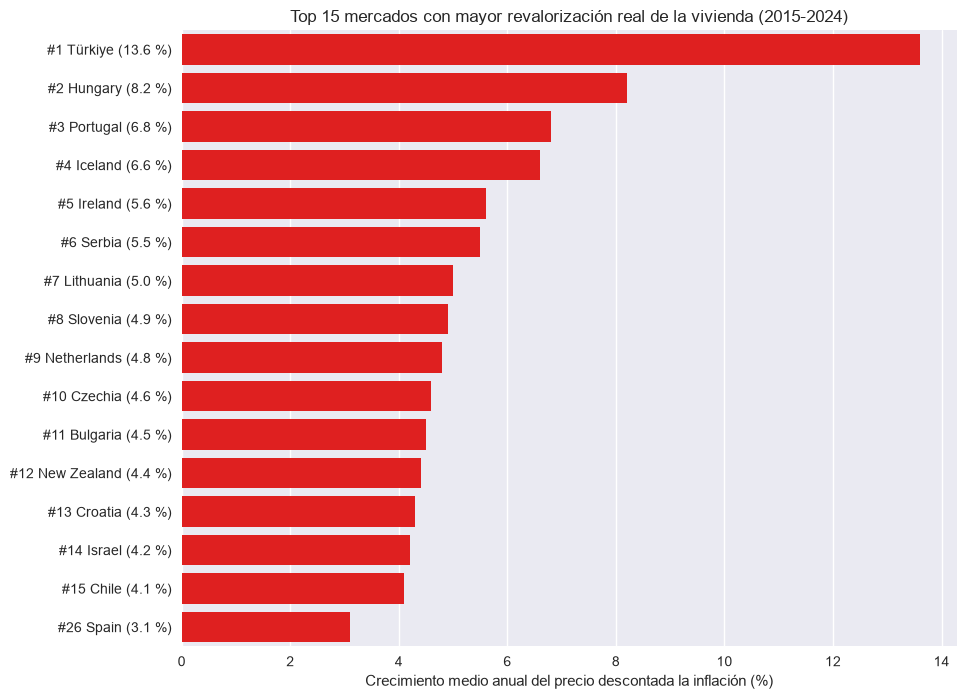

In [4]:
plt.style.use("seaborn-v0_8")
plt.figure(figsize=(10, 8))

sns.barplot(data=top15_real, x="crec_real_(%)", y="etiqueta", color="red")

plt.title("Top 15 mercados con mayor revalorización real de la vivienda (2015-2024)")
plt.xlabel("Crecimiento medio anual del precio descontada la inflación (%)")
plt.ylabel("")
guardar_grafico("04_top15_revalorizacion_real.png")
plt.show()

## Lectura del gráfico

*(Escribe aquí en 1-2 frases qué se observa.)*